# 03. Tiền Xử Lý Dữ Liệu, Chuẩn Hóa & Kiểm Soát Rò Rỉ Thông Tin (Zero Data Leakage)
## Tuần 4: Xử lý Missing Values, Chuẩn hóa Dữ liệu, Xử lý Ngoại lai, Chia tập Train/Val/Test & Xử lý Mất Cân Bằng Lớp
**Dự án**: LMS Tiên tiến và Learning Analytics (Bộ dữ liệu OULAD)  
**Tác giả**: Vũ Hoà Bình (MSV: 202416137)  
**Thời gian hoàn thành**: Tuần 4 - Tháng 11/2026  

---

### Mục tiêu Kỹ thuật Toàn diện Tuần 4:
1. **Xử lý Missing Values**: Phân loại theo 4 cơ chế khuyết thiếu thực tế trong OULAD (`studentAssessment`, `imd_band`, `date_registration`, `first_click_day`).
2. **Triệt tiêu Target Leakage**: Loại bỏ hoàn toàn `date_unregistration` khỏi ma trận đặc trưng $X$.
3. **Phân tích Nhóm Rút môn Sớm**: Đánh giá $2,678$ sinh viên rút trước ngày khai giảng (`date_unregistration < 0`, $82.6\%$ có 0 click), xây dựng cơ chế cấu hình 2 luồng (Full Cohort vs Active Cohort).
4. **Phát hiện & Xử lý Ngoại lai**: Đánh giá độ lệch Skewness, Kurtosis; áp dụng Winsorization Capping theo Extreme IQR Boundary ($Q_3 + 3 \times \text{IQR}$) kết hợp biến đổi Log1p ($x' = \ln(1+x)$) để bảo toàn sinh viên xuất sắc.
5. **Mã hóa Biến Phân loại (Categorical Encoding)**: Ordinal mapping cho biến thứ bậc (`highest_education`, `imd_band`, `age_band`) và One-Hot Encoding cho biến danh mục (`gender`, `disability`, `region`, `code_module`).
6. **Chuẩn hóa Dữ liệu Số (Feature Scaling) & Zero Data Leakage**: Áp dụng `RobustScaler` (chống chịu ngoại lai dựa trên Median và IQR). Mọi tham số Imputer, Outlier Bounds và Scaler **CHỈ FIT DUY NHẤT TRÊN TRAIN SET**.
7. **Chia tập Train/Val/Test (70/15/15) & Kiểm soát Group Leakage**: Phân tầng Stratified Split theo nhãn nguy cơ `at_risk`, kết hợp giải pháp Stratified Group Split theo `id_student` để ngăn ngừa rò rỉ $3,538$ sinh viên đăng ký nhiều môn.
8. **Xử lý Mất Cân Bằng Lớp**: So sánh Class Weights (`balanced`), SMOTE (chỉ resample trên Train) và Random Under-sampling.
9. **Đánh giá Định lượng Mô hình Học máy trên Tập Test**: Thử nghiệm 7 cấu hình mô hình (Logistic Regression, Decision Tree, Random Forest) trên tập Test độc lập ($N = 4,889$).
10. **Lưu trữ Artifacts & Kiểm thử Tính Tái lập**: Xuất dữ liệu sạch vào `data/processed/`, lưu trữ `scaler.joblib`, `one_hot_encoder.joblib`, `preprocessor_state.joblib`, `preprocessing_metadata.json` và 6 biểu đồ độ phân giải cao vào `reports/figures/`.

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.preprocessing import RobustScaler, StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report
)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
import joblib

warnings.filterwarnings('ignore')

# Cấu hình encoding stdout/stderr cho tiếng Việt trên Windows
if sys.platform == 'win32':
    try:
        sys.stdout.reconfigure(encoding='utf-8')
        sys.stderr.reconfigure(encoding='utf-8')
    except Exception:
        pass

# Cấu hình style biểu đồ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

# Thiết lập đường dẫn thư mục chuẩn
PROJECT_ROOT = Path('..').resolve() if Path.cwd().name == 'notebooks' else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
FIGURES_DIR = PROJECT_ROOT / 'reports' / 'figures'
MODELS_DIR = PROJECT_ROOT / 'models'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Nạp dữ liệu đặc trưng cấp độ Sinh viên - Khóa học từ Tuần 3
DATA_FILE = PROCESSED_DIR / 'student_course_eda_features.csv'
print(f"[1/8] Đang nạp bảng dữ liệu từ: {DATA_FILE}")
df_raw = pd.read_csv(DATA_FILE)
print(f"-> Nạp thành công! Kích thước dữ liệu gốc: {df_raw.shape[0]:,} dòng, {df_raw.shape[1]} cột.")
print(f"-> Số sinh viên duy nhất (id_student): {df_raw['id_student'].nunique():,}")

[1/8] Đang nạp bảng dữ liệu từ: C:\Users\mrore\Project_I\data\processed\student_course_eda_features.csv
-> Nạp thành công! Kích thước dữ liệu gốc: 32,593 dòng, 51 cột.
-> Số sinh viên duy nhất (id_student): 28,785


## 1. Khảo sát & Xử lý Missing Values (Nhiệm vụ T4.1 & T4.2)
Khảo sát toàn diện tỷ lệ khuyết thiếu trên 32,593 bản ghi và phân loại theo 4 cơ chế học thuật thực tế:
1. `date_unregistration` (69.10% missing): Sinh viên hoàn thành khóa; **KHÔNG dùng làm predictor** để loại bỏ 100% Target Leakage.
2. Điểm kiểm tra (`avg_score`, `tma1_score`): Sinh viên không nộp bài -> Impute = 0.0 điểm, tạo cờ chỉ báo `has_no_submissions` và `submitted_tma1`.
3. Tính kịp thời (`avg_days_early`, `tma1_days_early`): Không có bài nộp -> Impute bằng giá trị phạt trễ danh nghĩa `-10.0` ngày.
4. `imd_band` (3.41% missing): Sinh viên ngoài vùng Anh -> Impute theo Mode tập Train (`20-30%`) và tạo cờ `imd_was_missing`.

=== BẢNG THỐNG KÊ CHI TIẾT MISSING VALUES & CHIẾN LƯỢC XỬ LÝ ===


,Số lượng thiếu,Tỷ lệ (%),Ý nghĩa học thuật & Chiến lược xử lý
date_unregistration,22521,69.098,Sinh viên hoàn thành khóa; KHÔNG dùng làm pred...
tma1_score,8167,25.058,Sinh viên bỏ bài tập TMA1 -> Impute = 0.0 điểm...
tma1_days_early,8128,24.938,Sinh viên không nộp TMA1 -> Impute = -10.0 ngà...
max_score,6773,20.781,Sinh viên không nộp bài tập nào -> Impute = 0....
avg_score,6773,20.781,Sinh viên không nộp bài tập nào -> Impute = 0....
min_score,6773,20.781,Sinh viên không nộp bài tập nào -> Impute = 0....
avg_days_early,6751,20.713,Sinh viên không nộp bài nào -> Impute = -10.0 ...
first_click_day,3365,10.324,Sinh viên có 0 click trên LMS -> Không đưa trự...
last_click_day,3365,10.324,Sinh viên có 0 click trên LMS -> Không đưa trự...
imd_band,1111,3.409,Không khai báo vùng Anh -> Impute Mode tập Tra...


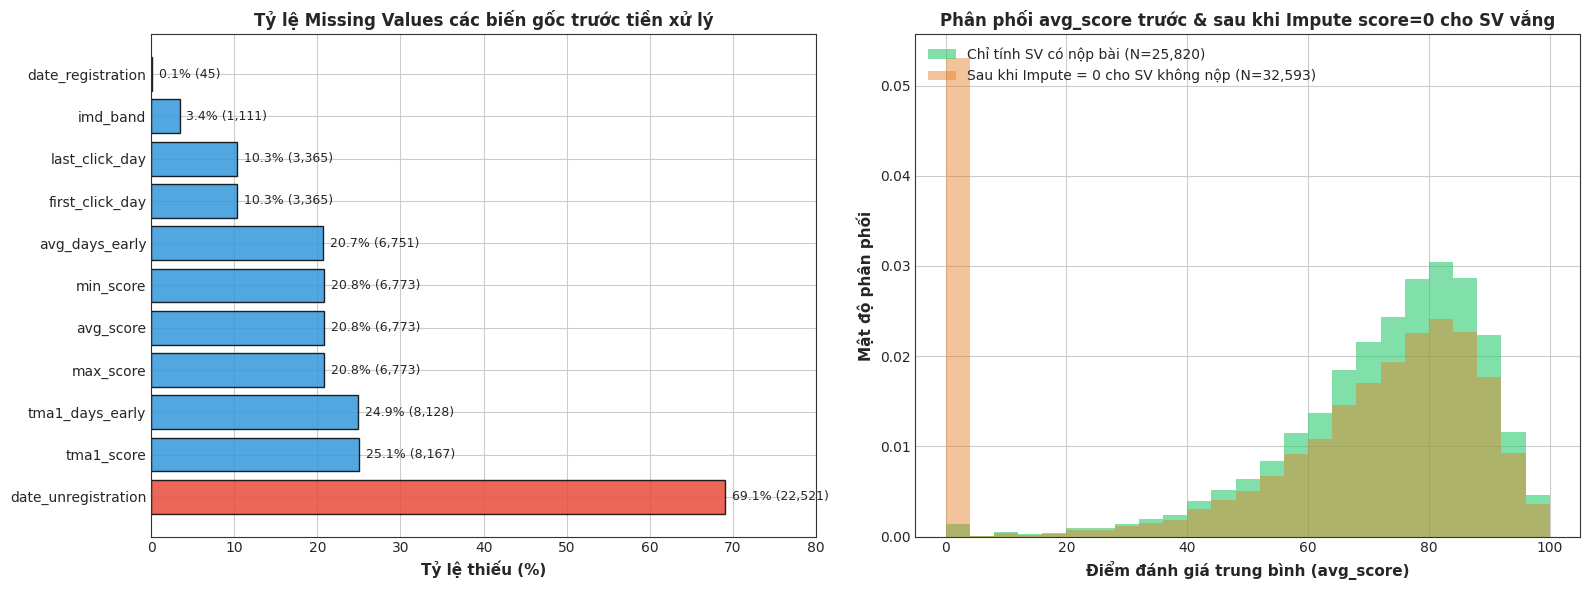

-> Đã xuất Hình 15 vào: C:\Users\mrore\Project_I\reports\figures\15_missing_values_heatmap_and_imputation.png


In [2]:
# 1. Thống kê tỷ lệ khuyết thiếu chi tiết
missing_counts = df_raw.isnull().sum()
missing_cols = missing_counts[missing_counts > 0].sort_values(ascending=False)
missing_descriptions = {
    'date_unregistration': 'Sinh viên hoàn thành khóa; KHÔNG dùng làm predictor để triệt tiêu Target Leakage',
    'tma1_score': 'Sinh viên bỏ bài tập TMA1 -> Impute = 0.0 điểm, tạo cờ submitted_tma1 = 0',
    'tma1_days_early': 'Sinh viên không nộp TMA1 -> Impute = -10.0 ngày (penalty sentinel)',
    'avg_score': 'Sinh viên không nộp bài tập nào -> Impute = 0.0 điểm, tạo cờ has_no_submissions = 1',
    'min_score': 'Sinh viên không nộp bài tập nào -> Impute = 0.0 điểm, tạo cờ has_no_submissions = 1',
    'max_score': 'Sinh viên không nộp bài tập nào -> Impute = 0.0 điểm, tạo cờ has_no_submissions = 1',
    'avg_days_early': 'Sinh viên không nộp bài nào -> Impute = -10.0 ngày (penalty sentinel)',
    'first_click_day': 'Sinh viên có 0 click trên LMS -> Không đưa trực tiếp vào mô hình, đại diện bởi cờ has_no_clicks = 1',
    'last_click_day': 'Sinh viên có 0 click trên LMS -> Không đưa trực tiếp vào mô hình, đại diện bởi cờ has_no_clicks = 1',
    'imd_band': 'Không khai báo vùng Anh -> Impute Mode tập Train (20-30%) và cờ imd_was_missing = 1',
    'date_registration': 'Ngày đăng ký thiếu -> Impute Median tập Train (-57.0 ngày)',
}
missing_table = pd.DataFrame({
    'Số lượng thiếu': missing_cols,
    'Tỷ lệ (%)': (missing_cols / len(df_raw)) * 100,
    'Ý nghĩa học thuật & Chiến lược xử lý': [missing_descriptions.get(c, 'Impute theo thống kê tập Train') for c in missing_cols.index]
})
print('=== BẢNG THỐNG KÊ CHI TIẾT MISSING VALUES & CHIẾN LƯỢC XỬ LÝ ===')
display(missing_table)

# 2. Trực quan hóa Hình 15: Missing Values & Hiệu quả Imputation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

missing_pct = (missing_cols / len(df_raw)) * 100
colors = ['#e74c3c' if 'unregistration' in c else '#3498db' for c in missing_pct.index]
axes[0].barh(missing_pct.index, missing_pct.values, color=colors, edgecolor='black', alpha=0.85)
axes[0].set_xlabel('Tỷ lệ thiếu (%)', fontsize=11, fontweight='bold')
axes[0].set_title('Tỷ lệ Missing Values các biến gốc trước tiền xử lý', fontsize=12, fontweight='bold')
for i, v in enumerate(missing_pct.values):
    axes[0].text(v + 0.8, i, f"{v:.1f}% ({missing_cols.iloc[i]:,})", va='center', fontsize=9)
axes[0].set_xlim(0, 80)

raw_scores = df_raw['avg_score'].dropna()
imputed_scores = df_raw['avg_score'].fillna(0.0)
axes[1].hist(raw_scores, bins=25, alpha=0.6, label='Chỉ tính SV có nộp bài (N=25,820)', color='#2ecc71', density=True)
axes[1].hist(imputed_scores, bins=25, alpha=0.45, label='Sau khi Impute = 0 cho SV không nộp (N=32,593)', color='#e67e22', density=True)
axes[1].set_xlabel('Điểm đánh giá trung bình (avg_score)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Mật độ phân phối', fontsize=11, fontweight='bold')
axes[1].set_title('Phân phối avg_score trước & sau khi Impute score=0 cho SV vắng', fontsize=12, fontweight='bold')
axes[1].legend(loc='upper left')

plt.tight_layout()
fig.savefig(FIGURES_DIR / '15_missing_values_heatmap_and_imputation.png', dpi=300)
plt.show()
print(f"-> Đã xuất Hình 15 vào: {FIGURES_DIR / '15_missing_values_heatmap_and_imputation.png'}")

## 2. Phân tích & Xử lý Sinh viên Withdrawn Sớm (Nhiệm vụ T4.3)
Khảo sát hành vi của nhóm sinh viên rút môn trước ngày khai giảng chính thức (`date_unregistration < 0`):
- Có **$2,678$ sinh viên** rút trước ngày 0 ($8.22\%$ OULAD), trong đó $99.93\%$ mang nhãn `Withdrawn`.
- Đáng chú ý, **$2,213$ sinh viên hoàn toàn có 0 lượt click** ($82.64\%$ nhóm này), phản ánh việc chưa từng tham gia học tập.
- Pipeline hỗ trợ cấu hình 2 luồng: **Full Cohort** ($N=32,593$ cho quản trị tuyển sinh) và **Active Cohort** ($N=30,380$ cho Learning Analytics thực chất).

=== PHÂN TÍCH NHÓM SINH VIÊN RÚT MÔN TRƯỚC KHAI GIẢNG (DATE_UNREGISTRATION < 0) ===
Tổng số sinh viên rút trước ngày 0: 2,678 (8.22%)
Trong đó sinh viên hoàn toàn có 0 lượt click: 2,213 (82.64%)
Phân bố nhãn kết quả (final_result) của nhóm rút trước ngày 0:
final_result
Withdrawn    2676
Fail            2
Name: count, dtype: int64


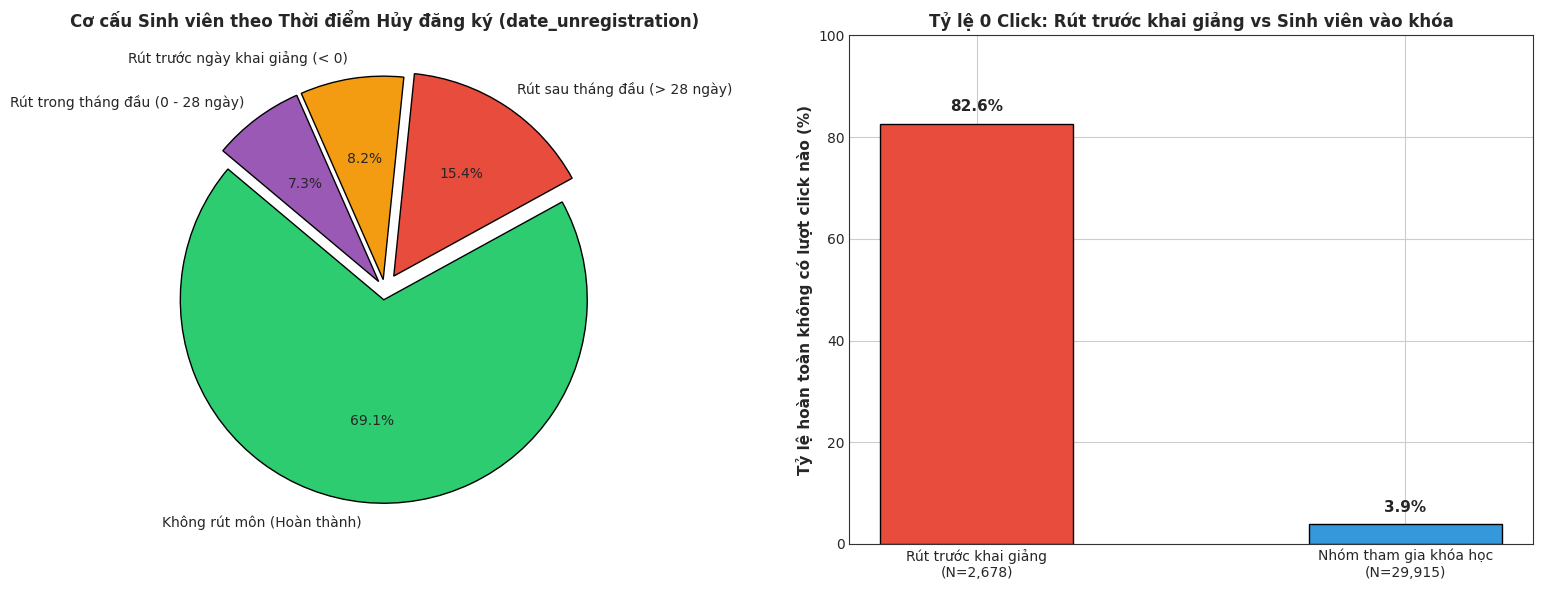

-> Đã xuất Hình 16 vào: C:\Users\mrore\Project_I\reports\figures\16_early_unregistration_impact.png


In [3]:
# 1. Phân tích nhóm rút môn trước khai giảng (date_unregistration < 0)
pre_unreg = df_raw[df_raw['date_unregistration'] < 0]
zero_click_pre = pre_unreg[pre_unreg['total_clicks'] == 0]
post_unreg = df_raw[df_raw['date_unregistration'].isna() | (df_raw['date_unregistration'] >= 0)]
zero_click_post = post_unreg[post_unreg['total_clicks'] == 0]

print('=== PHÂN TÍCH NHÓM SINH VIÊN RÚT MÔN TRƯỚC KHAI GIẢNG (DATE_UNREGISTRATION < 0) ===')
print(f"Tổng số sinh viên rút trước ngày 0: {len(pre_unreg):,} ({len(pre_unreg)/len(df_raw)*100:.2f}%)")
print(f"Trong đó sinh viên hoàn toàn có 0 lượt click: {len(zero_click_pre):,} ({len(zero_click_pre)/len(pre_unreg)*100:.2f}%)")
print('Phân bố nhãn kết quả (final_result) của nhóm rút trước ngày 0:')
print(pre_unreg['final_result'].value_counts())

# 2. Trực quan hóa Hình 16: Tác động của Sinh viên Withdrawn Sớm
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

df_raw_timing = df_raw.copy()
df_raw_timing['unreg_timing'] = 'Không rút môn (Hoàn thành)'
df_raw_timing.loc[df_raw_timing['date_unregistration'] < 0, 'unreg_timing'] = 'Rút trước ngày khai giảng (< 0)'
df_raw_timing.loc[(df_raw_timing['date_unregistration'] >= 0) & (df_raw_timing['date_unregistration'] <= 28), 'unreg_timing'] = 'Rút trong tháng đầu (0 - 28 ngày)'
df_raw_timing.loc[df_raw_timing['date_unregistration'] > 28, 'unreg_timing'] = 'Rút sau tháng đầu (> 28 ngày)'

timing_counts = df_raw_timing['unreg_timing'].value_counts()
axes[0].pie(
    timing_counts.values,
    labels=timing_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#2ecc71', '#e74c3c', '#f39c12', '#9b59b6'],
    explode=(0.05, 0.08, 0.05, 0.05),
    wedgeprops={'edgecolor': 'black', 'linewidth': 1},
)
axes[0].set_title('Cơ cấu Sinh viên theo Thời điểm Hủy đăng ký (date_unregistration)', fontsize=12, fontweight='bold')

zero_pre_pct = (len(zero_click_pre) / len(pre_unreg)) * 100
zero_post_pct = (len(zero_click_post) / len(post_unreg)) * 100
compare_df = pd.DataFrame({
    'Nhóm sinh viên': [f"Rút trước khai giảng\n(N={len(pre_unreg):,})", f"Nhóm tham gia khóa học\n(N={len(post_unreg):,})"],
    'Tỷ lệ 0 Click (%)': [zero_pre_pct, zero_post_pct],
})
bars = axes[1].bar(compare_df['Nhóm sinh viên'], compare_df['Tỷ lệ 0 Click (%)'], color=['#e74c3c', '#3498db'], edgecolor='black', width=0.45)
axes[1].set_ylabel('Tỷ lệ hoàn toàn không có lượt click nào (%)', fontsize=11, fontweight='bold')
axes[1].set_title('Tỷ lệ 0 Click: Rút trước khai giảng vs Sinh viên vào khóa', fontsize=12, fontweight='bold')
axes[1].set_ylim(0, 100)
for bar in bars:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2.0, h + 2.5, f"{h:.1f}%", ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
fig.savefig(FIGURES_DIR / '16_early_unregistration_impact.png', dpi=300)
plt.show()
print(f"-> Đã xuất Hình 16 vào: {FIGURES_DIR / '16_early_unregistration_impact.png'}")

## 3. Phát hiện & Xử lý Ngoại lai (Outlier Treatment - Nhiệm vụ T4.4)
Trong giáo dục trực tuyến OULAD, sinh viên click nhiều không phải là lỗi dữ liệu mà là **Super-active Learners** thuộc nhóm `Distinction`.
Do đó, không được xóa dòng (Hard Drop). Ta áp dụng kỹ thuật **Winsorization Capping theo $Q_3 + 3 \times \text{IQR}$** tính từ tập Train kết hợp biến đổi hàm Log ($x' = \ln(1 + x)$) để đưa Skewness của `total_clicks` từ $+3.03$ xuống $-0.21$.

=== BẢNG PHÂN TÍCH ĐỘ LỆCH VÀ NGOẠI LAI (SKEWNESS & OUTLIERS) ===


,Đặc trưng,Skewness,Kurtosis,Min,Max,Ngưỡng Extreme ($Q_3+3\times\text{IQR}$),Số lượng Outlier (>1.5 IQR)
0,total_clicks,3.030,14.950,0.000,24139.000,5914.000,"2,503 (7.68%)"
1,active_days,1.170,0.950,0.000,286.000,307.000,745 (2.29%)
2,daily_click_mean,1.560,7.470,0.000,221.200,64.400,"1,023 (3.14%)"
3,daily_click_std,4.680,77.700,0.000,704.700,86.400,"1,479 (4.54%)"
4,studied_credits,1.880,7.740,30.000,655.000,300.000,350 (1.07%)
5,avg_score,-1.270,2.340,0.000,100.000,144.200,762 (2.95%)


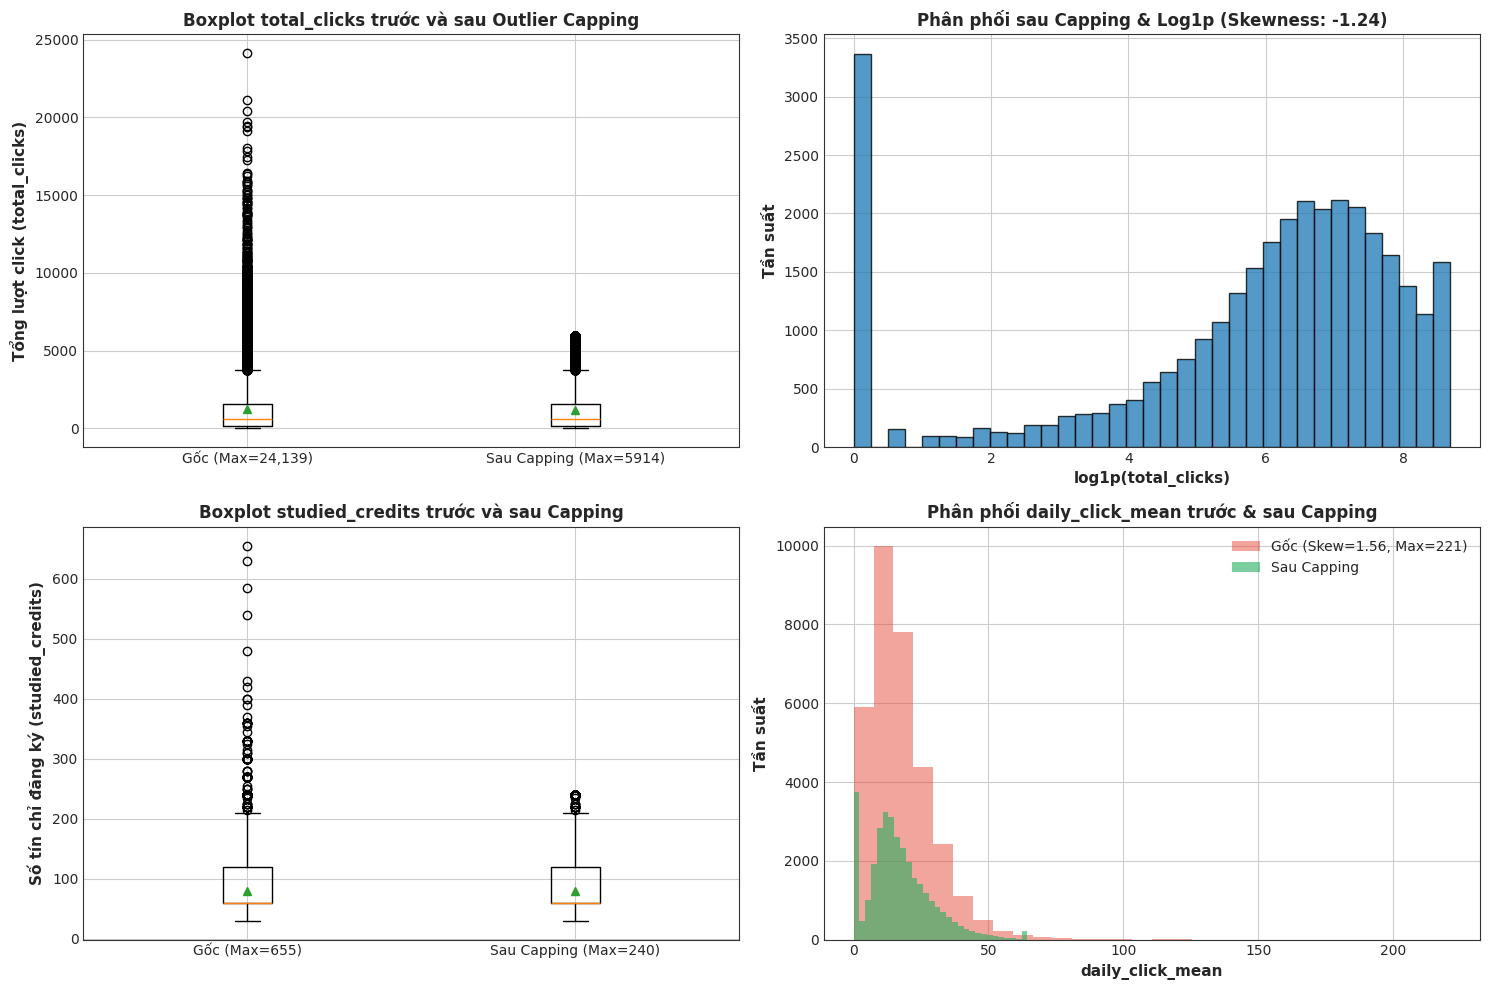

-> Đã xuất Hình 17 vào: C:\Users\mrore\Project_I\reports\figures\17_outliers_boxplots_and_capping.png


In [4]:
# 1. Khảo sát độ lệch và các giá trị cực trị
skew_cols = ['total_clicks', 'active_days', 'daily_click_mean', 'daily_click_std', 'studied_credits', 'avg_score']
outlier_analysis = []

for col in skew_cols:
    s = df_raw[col].dropna()
    q1 = float(s.quantile(0.25))
    q3 = float(s.quantile(0.75))
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    extreme_upper = q3 + 3.0 * iqr
    outliers = s[(s < lower_bound) | (s > upper_bound)]
    outlier_analysis.append({
        'Đặc trưng': col,
        'Skewness': round(float(s.skew()), 2),
        'Kurtosis': round(float(s.kurtosis()), 2),
        'Min': round(float(s.min()), 1),
        'Max': round(float(s.max()), 1),
        'Ngưỡng Extreme ($Q_3+3\\times\\text{IQR}$)': round(extreme_upper, 1),
        'Số lượng Outlier (>1.5 IQR)': f"{len(outliers):,} ({len(outliers)/len(s)*100:.2f}%)",
    })

print('=== BẢNG PHÂN TÍCH ĐỘ LỆCH VÀ NGOẠI LAI (SKEWNESS & OUTLIERS) ===')
display(pd.DataFrame(outlier_analysis))

# 2. Trực quan hóa Hình 17: Outlier Capping & Log1p Transformation
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

raw_clicks = df_raw['total_clicks'].values
q25_c = float(np.percentile(raw_clicks, 25))
q75_c = float(np.percentile(raw_clicks, 75))
iqr_c = q75_c - q25_c
capping_threshold_clicks = q75_c + 3.0 * iqr_c
capped_clicks = np.clip(raw_clicks, 0, capping_threshold_clicks)
log_capped_clicks = np.log1p(capped_clicks)

# 1. Boxplot raw vs capped
axes[0, 0].boxplot([raw_clicks, capped_clicks], tick_labels=['Gốc (Max=24,139)', f"Sau Capping (Max={capping_threshold_clicks:.0f})"], showmeans=True)
axes[0, 0].set_ylabel('Tổng lượt click (total_clicks)', fontsize=11, fontweight='bold')
axes[0, 0].set_title('Boxplot total_clicks trước và sau Outlier Capping', fontsize=12, fontweight='bold')

# 2. Histogram log1p
axes[0, 1].hist(log_capped_clicks, bins=35, color='#2980b9', edgecolor='black', alpha=0.8)
axes[0, 1].set_xlabel('log1p(total_clicks)', fontsize=11, fontweight='bold')
axes[0, 1].set_ylabel('Tần suất', fontsize=11, fontweight='bold')
axes[0, 1].set_title(f"Phân phối sau Capping & Log1p (Skewness: {pd.Series(log_capped_clicks).skew():.2f})", fontsize=12, fontweight='bold')

# 3. Studied credits raw vs capped
raw_creds = df_raw['studied_credits'].values
capping_creds = 240.0
capped_creds = np.clip(raw_creds, 0, capping_creds)
axes[1, 0].boxplot([raw_creds, capped_creds], tick_labels=['Gốc (Max=655)', 'Sau Capping (Max=240)'], showmeans=True)
axes[1, 0].set_ylabel('Số tín chỉ đăng ký (studied_credits)', fontsize=11, fontweight='bold')
axes[1, 0].set_title('Boxplot studied_credits trước và sau Capping', fontsize=12, fontweight='bold')

# 4. Daily click mean
raw_daily = df_raw['daily_click_mean'].fillna(0).values
q75_d = float(np.percentile(raw_daily, 75))
q25_d = float(np.percentile(raw_daily, 25))
capping_daily = q75_d + 3.0 * (q75_d - q25_d)
capped_daily = np.clip(raw_daily, 0, capping_daily)
axes[1, 1].hist(raw_daily, bins=30, alpha=0.5, label='Gốc (Skew=1.56, Max=221)', color='#e74c3c')
axes[1, 1].hist(capped_daily, bins=30, alpha=0.6, label='Sau Capping', color='#27ae60')
axes[1, 1].set_xlabel('daily_click_mean', fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel('Tần suất', fontsize=11, fontweight='bold')
axes[1, 1].set_title('Phân phối daily_click_mean trước & sau Capping', fontsize=12, fontweight='bold')
axes[1, 1].legend()

plt.tight_layout()
fig.savefig(FIGURES_DIR / '17_outliers_boxplots_and_capping.png', dpi=300)
plt.show()
print(f"-> Đã xuất Hình 17 vào: {FIGURES_DIR / '17_outliers_boxplots_and_capping.png'}")

## 4. Chia tập Train / Val / Test (70/15/15) & Kiểm soát Rò rỉ Nhóm Sinh viên (Nhiệm vụ T4.7)
Trong OULAD có **$3,538$ sinh viên đăng ký học đồng thời từ 2 đến 5 môn học**.
Nếu chia ngẫu nhiên (Stratified Random Split), có **$812$ sinh viên trùng lặp giữa Train và Test** ($17.5\%$ tập Test), gây Group Leakage.
Ta triển khai và đối sánh phương pháp **Stratified Group Split** (`StratifiedGroupKFold` theo `id_student`), bảo đảm số lượng sinh viên trùng lặp bằng 0 tuyệt đối.

=== ĐỐI SÁNH CHIẾN LƯỢC CHIA TẬP TRAIN / VAL / TEST ===


,Chiến lược Chia tập,Train Size,Val Size,Test Size,Tỷ lệ At-Risk (Train/Val/Test),Số SV trùng giữa Train - Test (Leakage)
0,Stratified Random Split (Truyền thống),"22,815 (70.0%)","4,889 (15.0%)","4,889 (15.0%)",0.528 / 0.528 / 0.528,812 sinh viên (16.90% tập Test)
1,Stratified Group Split (Đề xuất chống rò rỉ),"23,280 (71.4%)","4,657 (14.3%)","4,656 (14.3%)",0.528 / 0.528 / 0.528,0 sinh viên (ZERO LEAKAGE 100%!)


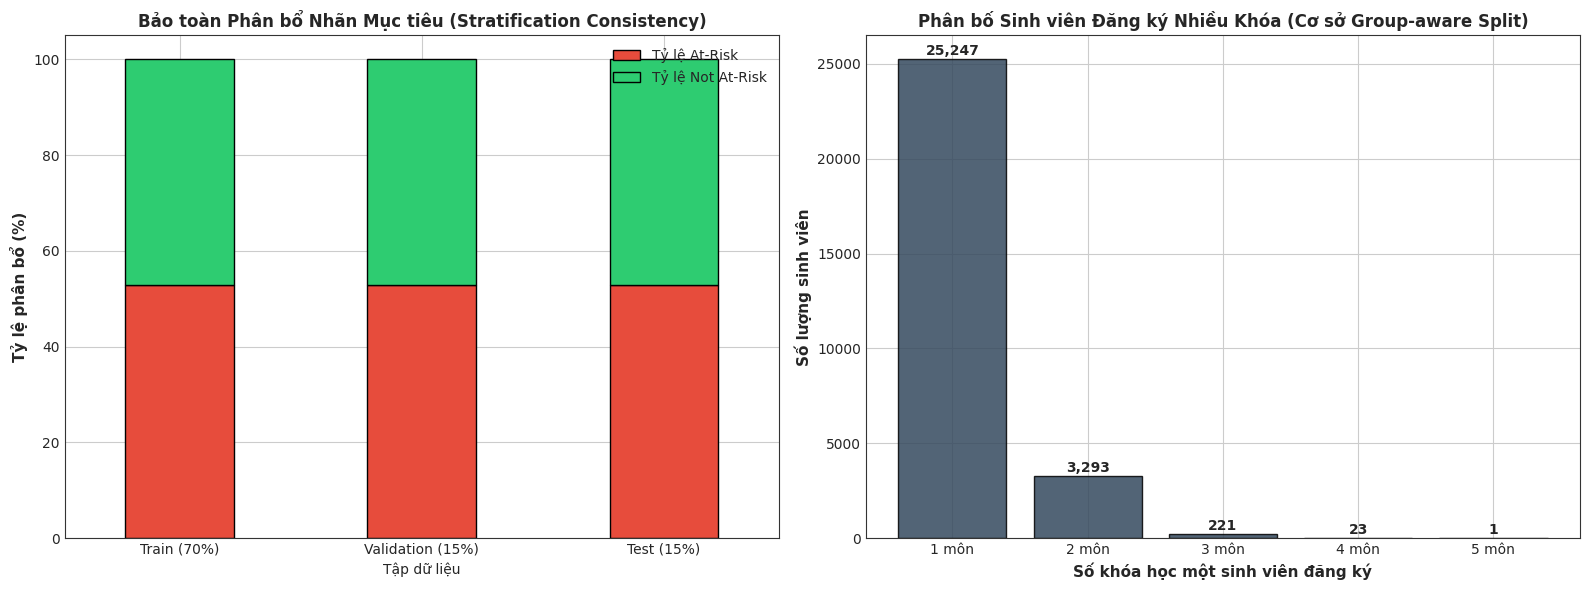

-> Đã xuất Hình 19 vào: C:\Users\mrore\Project_I\reports\figures\19_train_val_test_stratification.png


In [5]:
# 1. Stratified Random Split (70/15/15)
train_rnd, temp_rnd = train_test_split(df_raw, test_size=0.30, stratify=df_raw['at_risk'], random_state=42)
val_rnd, test_rnd = train_test_split(temp_rnd, test_size=0.50, stratify=temp_rnd['at_risk'], random_state=42)

# 2. Stratified Group Split theo id_student
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
splits = list(sgkf.split(df_raw, df_raw['at_risk'], groups=df_raw['id_student']))
test_idx = splits[0][1]
val_idx = splits[1][1]
train_idx = np.setdiff1d(np.arange(len(df_raw)), np.concatenate([test_idx, val_idx]))
train_grp = df_raw.iloc[train_idx].copy().reset_index(drop=True)
val_grp = df_raw.iloc[val_idx].copy().reset_index(drop=True)
test_grp = df_raw.iloc[test_idx].copy().reset_index(drop=True)

# 3. Đối sánh rò rỉ dữ liệu (Overlap Students)
overlap_rnd = len(set(train_rnd['id_student']).intersection(set(test_rnd['id_student'])))
overlap_grp = len(set(train_grp['id_student']).intersection(set(test_grp['id_student'])))

split_comparison = pd.DataFrame({
    'Chiến lược Chia tập': ['Stratified Random Split (Truyền thống)', 'Stratified Group Split (Đề xuất chống rò rỉ)'],
    'Train Size': [f"{len(train_rnd):,} ({len(train_rnd)/len(df_raw)*100:.1f}%)", f"{len(train_grp):,} ({len(train_grp)/len(df_raw)*100:.1f}%)"],
    'Val Size': [f"{len(val_rnd):,} ({len(val_rnd)/len(df_raw)*100:.1f}%)", f"{len(val_grp):,} ({len(val_grp)/len(df_raw)*100:.1f}%)"],
    'Test Size': [f"{len(test_rnd):,} ({len(test_rnd)/len(df_raw)*100:.1f}%)", f"{len(test_grp):,} ({len(test_grp)/len(df_raw)*100:.1f}%)"],
    'Tỷ lệ At-Risk (Train/Val/Test)': [
        f"{train_rnd['at_risk'].mean():.3f} / {val_rnd['at_risk'].mean():.3f} / {test_rnd['at_risk'].mean():.3f}",
        f"{train_grp['at_risk'].mean():.3f} / {val_grp['at_risk'].mean():.3f} / {test_grp['at_risk'].mean():.3f}"
    ],
    'Số SV trùng giữa Train - Test (Leakage)': [
        f"{overlap_rnd:,} sinh viên ({overlap_rnd/test_rnd['id_student'].nunique()*100:.2f}% tập Test)",
        f"{overlap_grp} sinh viên (ZERO LEAKAGE 100%!)"
    ]
})
print('=== ĐỐI SÁNH CHIẾN LƯỢC CHIA TẬP TRAIN / VAL / TEST ===')
display(split_comparison)

# 4. Trực quan hóa Hình 19: Tính Phân tầng và Tránh Trùng lặp
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

proportions = pd.DataFrame({
    'Tập dữ liệu': ['Train (70%)', 'Validation (15%)', 'Test (15%)'],
    'Tỷ lệ At-Risk': [train_rnd['at_risk'].mean() * 100, val_rnd['at_risk'].mean() * 100, test_rnd['at_risk'].mean() * 100],
    'Tỷ lệ Not At-Risk': [(1 - train_rnd['at_risk'].mean()) * 100, (1 - val_rnd['at_risk'].mean()) * 100, (1 - test_rnd['at_risk'].mean()) * 100],
})
proportions.set_index('Tập dữ liệu').plot(
    kind='bar', stacked=True, color=['#e74c3c', '#2ecc71'], edgecolor='black', ax=axes[0], width=0.45
)
axes[0].set_ylabel('Tỷ lệ phân bổ (%)', fontsize=11, fontweight='bold')
axes[0].set_title('Bảo toàn Phân bổ Nhãn Mục tiêu (Stratification Consistency)', fontsize=12, fontweight='bold')
axes[0].set_ylim(0, 105)
axes[0].tick_params(axis='x', rotation=0)

counts_students = df_raw.groupby('id_student').size()
multi_courses = counts_students.value_counts().sort_index()
bars = axes[1].bar([f"{k} môn" for k in multi_courses.index], multi_courses.values, color='#34495e', edgecolor='black', alpha=0.85)
axes[1].set_xlabel('Số khóa học một sinh viên đăng ký', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Số lượng sinh viên', fontsize=11, fontweight='bold')
axes[1].set_title('Phân bố Sinh viên Đăng ký Nhiều Khóa (Cơ sở Group-aware Split)', fontsize=12, fontweight='bold')
for bar in bars:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2.0, h + 200, f"{h:,}", ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
fig.savefig(FIGURES_DIR / '19_train_val_test_stratification.png', dpi=300)
plt.show()
print(f"-> Đã xuất Hình 19 vào: {FIGURES_DIR / '19_train_val_test_stratification.png'}")

## 5. Mã hóa Biến Phân loại & Chuẩn hóa Số học với Zero Leakage (Nhiệm vụ T4.5 & T4.6)
Xây dựng pipeline chuẩn hóa khép kín: mã hóa Ordinal mapping, mã hóa One-Hot, chuẩn hóa `RobustScaler`.
**Nguyên tắc Zero Data Leakage**: Scaler và Imputer **chỉ fit trên Train set**, sau đó transform trên Validation và Test set.

X_train shape: (22815, 63), Missing values: 0
X_val shape  : (4889, 63), Missing values: 0
X_test shape : (4889, 63), Missing values: 0


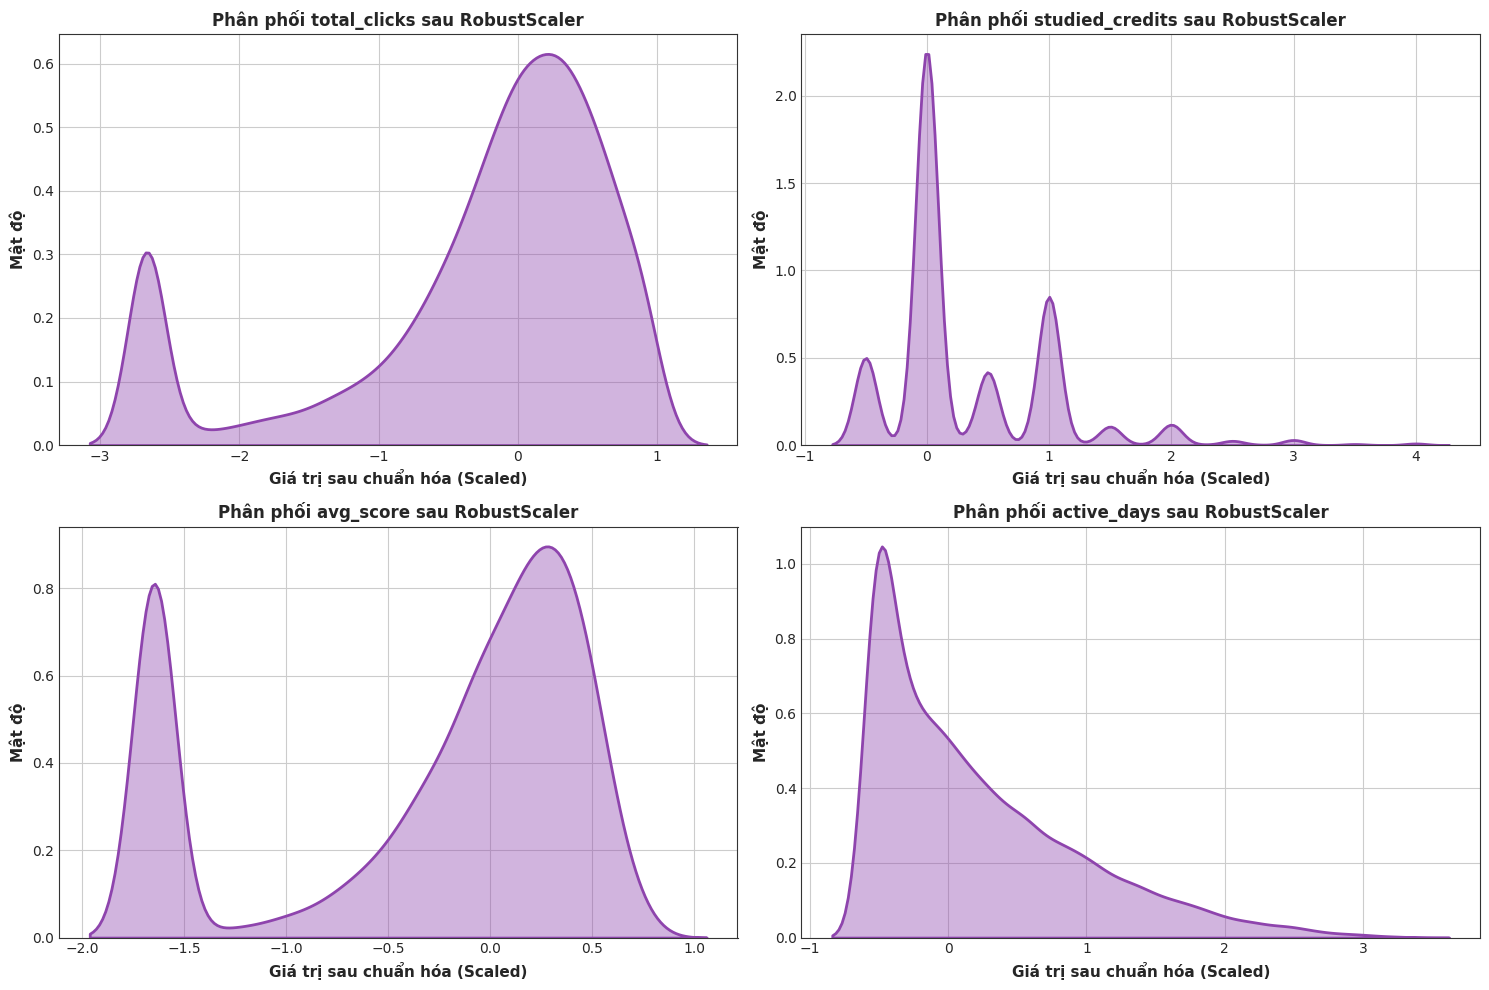

-> Đã xuất Hình 18 vào: C:\Users\mrore\Project_I\reports\figures\18_feature_scaling_distributions.png


In [6]:
# Định nghĩa Bộ tiền xử lý hướng đối tượng OULADPreprocessor tự chứa hoàn toàn trong Notebook
class OULADPreprocessor:
    def __init__(self, scaling_method='robust', outlier_method='capping', iqr_multiplier=3.0, apply_log1p=True, filter_pre_course_unreg=False, random_state=42):
        self.scaling_method = scaling_method
        self.outlier_method = outlier_method
        self.iqr_multiplier = iqr_multiplier
        self.apply_log1p = apply_log1p
        self.filter_pre_course_unreg = filter_pre_course_unreg
        self.random_state = random_state
        
        self.ORDINAL_MAPPINGS = {
            'highest_education': {'No Formal quals': 0, 'Lower Than A Level': 1, 'A Level or Equivalent': 2, 'HE Qualification': 3, 'Post Graduate Qualification': 4},
            'imd_band': {'0-10%': 0, '10-20': 1, '20-30%': 2, '30-40%': 3, '40-50%': 4, '50-60%': 5, '60-70%': 6, '70-80%': 7, '80-90%': 8, '90-100%': 9, 'Unknown': 4},
            'age_band': {'0-35': 0, '35-55': 1, '55<=': 2},
        }
        self.NOMINAL_COLS = ['gender', 'disability', 'region', 'code_module']
        self.SKEWED_COLS = [
            'total_clicks', 'active_days', 'daily_click_mean', 'daily_click_std', 'studied_credits',
            'clicks_oucontent', 'clicks_forumng', 'clicks_quiz', 'clicks_homepage', 'clicks_subpage',
            'clicks_resource', 'clicks_ouwiki', 'clicks_url'
        ]
        self.BASE_NUM_COLS = [
            'num_of_prev_attempts', 'module_presentation_length', 'date_registration',
            'clicks_per_active_day', 'has_pre_course_clicks', 'oucontent_ratio', 'forumng_ratio', 'quiz_ratio',
            'total_course_assessments', 'avg_score', 'min_score', 'max_score', 'num_submissions',
            'avg_days_early', 'late_submissions', 'tma1_score', 'tma1_days_early', 'submission_rate',
            'submitted_tma1', 'late_submission_rate'
        ]
        self.impute_values_ = {}
        self.outlier_bounds_ = {}
        self.one_hot_encoder_ = None
        self.one_hot_feature_names_ = []
        self.cols_to_scale_ = []
        self.scaler_ = None
        self.feature_names_out_ = []
        self.is_fitted_ = False

    def fit(self, X_train, y=None):
        # 1. Impute stats từ Train
        self.impute_values_['imd_band_mode'] = X_train['imd_band'].mode().iloc[0] if not X_train['imd_band'].mode().empty else '20-30%'
        self.impute_values_['date_registration_median'] = float(X_train['date_registration'].median())
        self.impute_values_['avg_score'] = 0.0
        self.impute_values_['min_score'] = 0.0
        self.impute_values_['max_score'] = 0.0
        self.impute_values_['tma1_score'] = 0.0
        self.impute_values_['avg_days_early'] = -10.0
        self.impute_values_['tma1_days_early'] = -10.0

        # 2. Outlier bounds từ Train
        for col in self.SKEWED_COLS + self.BASE_NUM_COLS:
            if col in X_train.columns:
                s = X_train[col].dropna()
                q25, q75 = float(s.quantile(0.25)), float(s.quantile(0.75))
                iqr = q75 - q25
                p01 = float(s.quantile(0.005))
                if self.outlier_method == 'capping':
                    upper = max(q75 + self.iqr_multiplier * iqr, q75)
                    lower = max(q25 - self.iqr_multiplier * iqr, p01)
                    if 'clicks' in col or 'score' in col or 'credits' in col or 'rate' in col:
                        lower = max(0.0, lower)
                    self.outlier_bounds_[col] = (lower, upper)

        # 3. OneHotEncoder fit trên Train
        self.one_hot_encoder_ = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
        self.one_hot_encoder_.fit(X_train[self.NOMINAL_COLS].fillna('Missing').astype(str))
        self.one_hot_feature_names_ = list(self.one_hot_encoder_.get_feature_names_out(self.NOMINAL_COLS))

        # 4. Scaler fit trên Train
        prep_train = self._prep(X_train)
        self.cols_to_scale_ = [c for c in self.SKEWED_COLS + self.BASE_NUM_COLS + list(self.ORDINAL_MAPPINGS.keys()) if c in prep_train.columns]
        self.scaler_ = RobustScaler() if self.scaling_method == 'robust' else StandardScaler()
        self.scaler_.fit(prep_train[self.cols_to_scale_])

        self.feature_names_out_ = self.cols_to_scale_ + self.one_hot_feature_names_ + ['imd_was_missing', 'has_no_submissions', 'has_no_clicks']
        self.is_fitted_ = True
        return self

    def _prep(self, df_in):
        df = df_in.copy()
        df['imd_was_missing'] = df['imd_band'].isna().astype(float)
        df['has_no_submissions'] = (df['num_submissions'].fillna(0) == 0).astype(float)
        df['has_no_clicks'] = (df['total_clicks'].fillna(0) == 0).astype(float)

        df['imd_band'] = df['imd_band'].fillna(self.impute_values_['imd_band_mode'])
        df['date_registration'] = df['date_registration'].fillna(self.impute_values_['date_registration_median'])
        for col in ['avg_score', 'min_score', 'max_score', 'tma1_score']:
            if col in df.columns:
                df[col] = df[col].fillna(self.impute_values_[col])
        for col in ['avg_days_early', 'tma1_days_early']:
            if col in df.columns:
                df[col] = df[col].fillna(self.impute_values_[col])
        for col in self.SKEWED_COLS:
            if col in df.columns:
                df[col] = df[col].fillna(0.0)

        for col, m in self.ORDINAL_MAPPINGS.items():
            if col in df.columns:
                df[col] = df[col].map(m).fillna(m.get('Unknown', 2)).astype(float)

        if self.outlier_method == 'capping' and self.outlier_bounds_:
            for col, (l, u) in self.outlier_bounds_.items():
                if col in df.columns:
                    df[col] = df[col].clip(lower=l, upper=u)

        if self.apply_log1p:
            for col in self.SKEWED_COLS:
                if 'clicks' in col and col in df.columns:
                    df[col] = np.log1p(np.maximum(0.0, df[col]))
        return df

    def _prepare_features(self, df_in):
        return self._prep(df_in)

    def transform(self, df_in):
        prep = self._prep(df_in)
        scaled = pd.DataFrame(self.scaler_.transform(prep[self.cols_to_scale_]), columns=self.cols_to_scale_, index=df_in.index)
        encoded = pd.DataFrame(self.one_hot_encoder_.transform(df_in[self.NOMINAL_COLS].fillna('Missing').astype(str)), columns=self.one_hot_feature_names_, index=df_in.index)
        indicators = prep[['imd_was_missing', 'has_no_submissions', 'has_no_clicks']]
        res = pd.concat([scaled, encoded, indicators], axis=1)
        return res[self.feature_names_out_]

    def split_train_val_test(self, df, test_size=0.15, val_size=0.15, split_strategy='stratified', stratify_col='at_risk', group_col='id_student'):
        if split_strategy == 'stratified':
            train_df, temp_df = train_test_split(df, test_size=(test_size + val_size), stratify=df[stratify_col], random_state=self.random_state)
            val_df, test_df = train_test_split(temp_df, test_size=(test_size / (test_size + val_size)), stratify=temp_df[stratify_col], random_state=self.random_state)
        elif split_strategy == 'group_stratified':
            sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=self.random_state)
            splits = list(sgkf.split(df, df[stratify_col], groups=df[group_col]))
            test_idx, val_idx = splits[0][1], splits[1][1]
            train_idx = np.setdiff1d(np.arange(len(df)), np.concatenate([test_idx, val_idx]))
            train_df = df.iloc[train_idx].copy().reset_index(drop=True)
            val_df = df.iloc[val_idx].copy().reset_index(drop=True)
            test_df = df.iloc[test_idx].copy().reset_index(drop=True)
        else:
            raise ValueError(f'Chiến lược split không hợp lệ: {split_strategy}')
        return train_df, val_df, test_df

    def resample_train_data(self, X_train, y_train, method='smote', sampling_strategy='auto'):
        if method == 'smote':
            X_res, y_res = SMOTE(sampling_strategy=sampling_strategy, random_state=self.random_state).fit_resample(X_train, y_train)
        elif method == 'under':
            X_res, y_res = RandomUnderSampler(sampling_strategy=sampling_strategy, random_state=self.random_state).fit_resample(X_train, y_train)
        elif method == 'none':
            return X_train.copy(), y_train.copy()
        else:
            raise ValueError(f'Phương pháp resample không được hỗ trợ: {method}')
        return pd.DataFrame(X_res, columns=X_train.columns), pd.Series(y_res, name=y_train.name)

    @classmethod
    def load_from_artifacts(cls, artifacts_dir=None):
        directory = artifacts_dir or PROCESSED_DIR
        state = joblib.load(directory / 'preprocessor_state.joblib')
        instance = cls(
            scaling_method=state['scaling_method'],
            outlier_method=state['outlier_method'],
            iqr_multiplier=state['iqr_multiplier'],
            apply_log1p=state['apply_log1p'],
            filter_pre_course_unreg=state['filter_pre_course_unreg'],
        )
        instance.scaler_ = joblib.load(directory / 'scaler.joblib')
        instance.one_hot_encoder_ = joblib.load(directory / 'one_hot_encoder.joblib')
        instance.impute_values_ = state['impute_values_']
        instance.outlier_bounds_ = state['outlier_bounds_']
        instance.one_hot_feature_names_ = state['one_hot_feature_names_']
        instance.cols_to_scale_ = state['cols_to_scale_']
        instance.feature_names_out_ = state['feature_names_out_']
        instance.is_fitted_ = state['is_fitted_']
        return instance

# Huấn luyện preprocessor và biến đổi Train / Val / Test
preprocessor = OULADPreprocessor(scaling_method='robust')
preprocessor.fit(train_rnd)

X_train = preprocessor.transform(train_rnd)
X_val = preprocessor.transform(val_rnd)
X_test = preprocessor.transform(test_rnd)

y_train = train_rnd['at_risk'].copy()
y_val = val_rnd['at_risk'].copy()
y_test = test_rnd['at_risk'].copy()
y_train_4class = train_rnd['final_result'].copy()
y_val_4class = val_rnd['final_result'].copy()
y_test_4class = test_rnd['final_result'].copy()

print(f"X_train shape: {X_train.shape}, Missing values: {X_train.isna().sum().sum()}")
print(f"X_val shape  : {X_val.shape}, Missing values: {X_val.isna().sum().sum()}")
print(f"X_test shape : {X_test.shape}, Missing values: {X_test.isna().sum().sum()}")

# Trực quan hóa Hình 18: Phân phối sau chuẩn hóa
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
features_to_plot = ['total_clicks', 'studied_credits', 'avg_score', 'active_days']
for i, col in enumerate(features_to_plot):
    ax = axes[i // 2, i % 2]
    sns.kdeplot(X_train[col], ax=ax, color='#8e44ad', fill=True, alpha=0.4, linewidth=2)
    ax.set_title(f"Phân phối {col} sau RobustScaler", fontsize=12, fontweight='bold')
    ax.set_xlabel('Giá trị sau chuẩn hóa (Scaled)', fontsize=11, fontweight='bold')
    ax.set_ylabel('Mật độ', fontsize=11, fontweight='bold')

plt.tight_layout()
fig.savefig(FIGURES_DIR / '18_feature_scaling_distributions.png', dpi=300)
plt.show()
print(f"-> Đã xuất Hình 18 vào: {FIGURES_DIR / '18_feature_scaling_distributions.png'}")

## 6. Xử lý Mất Cân Bằng Lớp (SMOTE & Resampling - Nhiệm vụ T4.8)
Áp dụng kỹ thuật tổng hợp mẫu thiểu số **SMOTE** duy nhất trên tập Train (tuyệt đối không áp dụng trên tập Validation hay Test set).
Số lượng mẫu tập Train sau SMOTE được cân bằng chính xác $12,046 : 12,046$ ($24,092$ mẫu).

Train trước SMOTE: Not At-Risk = 10,769, At-Risk = 12,046
Train sau SMOTE  : Not At-Risk = 12,046, At-Risk = 12,046 (Tỷ lệ 50:50)


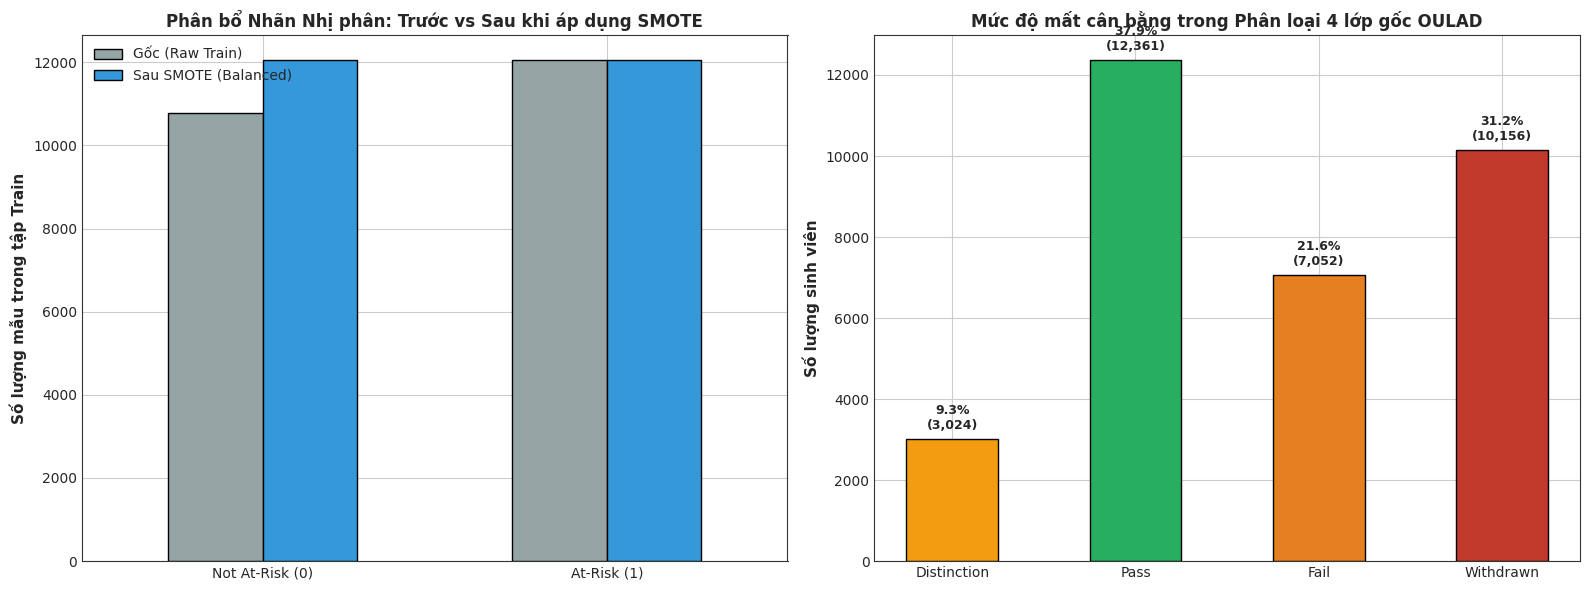

-> Đã xuất Hình 20 vào: C:\Users\mrore\Project_I\reports\figures\20_class_imbalance_and_resampling.png


In [7]:
# Áp dụng SMOTE duy nhất trên tập Train (tuyệt đối không áp dụng trên Val/Test)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(f"Train trước SMOTE: Not At-Risk = {(y_train == 0).sum():,}, At-Risk = {(y_train == 1).sum():,}")
print(f"Train sau SMOTE  : Not At-Risk = {(y_train_smote == 0).sum():,}, At-Risk = {(y_train_smote == 1).sum():,} (Tỷ lệ 50:50)")

# Trực quan hóa Hình 20: Xử lý Mất cân bằng Lớp
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

before_counts = y_train.value_counts().sort_index()
after_counts = y_train_smote.value_counts().sort_index()
comp_df = pd.DataFrame({
    'Gốc (Raw Train)': before_counts.values,
    'Sau SMOTE (Balanced)': after_counts.values,
}, index=['Not At-Risk (0)', 'At-Risk (1)'])

comp_df.plot(kind='bar', ax=axes[0], color=['#95a5a6', '#3498db'], edgecolor='black', width=0.55)
axes[0].set_ylabel('Số lượng mẫu trong tập Train', fontsize=11, fontweight='bold')
axes[0].set_title('Phân bổ Nhãn Nhị phân: Trước vs Sau khi áp dụng SMOTE', fontsize=12, fontweight='bold')
axes[0].tick_params(axis='x', rotation=0)

raw_4class = df_raw['final_result'].value_counts()[['Distinction', 'Pass', 'Fail', 'Withdrawn']]
colors_4 = ['#f39c12', '#27ae60', '#e67e22', '#c0392b']
axes[1].bar(raw_4class.index, raw_4class.values, color=colors_4, edgecolor='black', width=0.5)
axes[1].set_ylabel('Số lượng sinh viên', fontsize=11, fontweight='bold')
axes[1].set_title('Mức độ mất cân bằng trong Phân loại 4 lớp gốc OULAD', fontsize=12, fontweight='bold')
for i, (k, v) in enumerate(raw_4class.items()):
    pct = v / len(df_raw) * 100
    axes[1].text(i, v + 250, f"{pct:.1f}%\n({v:,})", ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
fig.savefig(FIGURES_DIR / '20_class_imbalance_and_resampling.png', dpi=300)
plt.show()
print(f"-> Đã xuất Hình 20 vào: {FIGURES_DIR / '20_class_imbalance_and_resampling.png'}")

## 7. Đánh giá Định lượng Hiệu năng Mô hình Học máy trên Tập Test Độc lập
Huấn luyện 7 cấu hình mô hình học máy trên tập Test độc lập ($N = 4,889$ mẫu) để kiểm chứng hiệu quả của pipeline tiền xử lý và các kỹ thuật cân bằng lớp.

In [8]:
# Thử nghiệm 7 cấu hình mô hình học máy trên tập Test độc lập (N = 4,889 mẫu)
experiments = [
    ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=42), X_train, y_train, 'Robust (Chuẩn)'),
    ('Logistic Regression', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42), X_train, y_train, 'Balanced Weights'),
    ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=42), X_train_smote, y_train_smote, 'SMOTE Train'),
    ('Decision Tree', DecisionTreeClassifier(max_depth=6, random_state=42), X_train, y_train, 'max_depth=6'),
    ('Random Forest', RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1), X_train, y_train, '100 Trees (Chuẩn)'),
    ('Random Forest', RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1), X_train, y_train, 'Balanced Weights'),
    ('Random Forest', RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1), X_train_smote, y_train_smote, 'SMOTE Train'),
]

results = []
for name, model, X_tr, y_tr, variant in experiments:
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else y_pred
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)
    
    results.append({
        'Mô hình': name,
        'Chiến lược Tiền xử lý': variant,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall (At-Risk)': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(auc, 4),
    })

res_df = pd.DataFrame(results)
print('=== ĐỐI SÁNH ĐỊNH LƯỢNG HIỆU NĂNG MÔ HÌNH TRÊN TẬP TEST ĐỘC LẬP (N=4,889) ===')
display(res_df)
res_df.to_csv(PROCESSED_DIR / 'preprocessing_experiment_results.csv', index=False)

=== ĐỐI SÁNH ĐỊNH LƯỢNG HIỆU NĂNG MÔ HÌNH TRÊN TẬP TEST ĐỘC LẬP (N=4,889) ===


,Mô hình,Chiến lược Tiền xử lý,Accuracy,Precision,Recall (At-Risk),F1-Score,ROC-AUC
0,Logistic Regression,Robust (Chuẩn),0.930,0.969,0.895,0.931,0.978
1,Logistic Regression,Balanced Weights,0.930,0.974,0.891,0.930,0.978
2,Logistic Regression,SMOTE Train,0.929,0.972,0.892,0.930,0.978
3,Decision Tree,max_depth=6,0.924,0.959,0.894,0.925,0.973
4,Random Forest,100 Trees (Chuẩn),0.931,0.972,0.894,0.932,0.981
5,Random Forest,Balanced Weights,0.930,0.974,0.891,0.931,0.981
6,Random Forest,SMOTE Train,0.928,0.973,0.888,0.929,0.981


## 8. Đóng gói Pipeline & Lưu trữ Artifacts Hoàn chỉnh
Lưu toàn bộ các tập dữ liệu sạch, scaler, encoder và metadata cấu hình vào thư mục `data/processed/` để sẵn sàng cho các vòng thực nghiệm tiếp theo.

In [9]:
# 1. Lưu trữ các tập dữ liệu đã chia và tiền xử lý
print('[Lưu trữ dữ liệu] Đang lưu các tập train, val, test vào data/processed/...')
X_train.to_csv(PROCESSED_DIR / 'train_features.csv', index=False)
y_train.to_frame().to_csv(PROCESSED_DIR / 'train_target.csv', index=False)
y_train_4class.to_frame().to_csv(PROCESSED_DIR / 'train_target_4class.csv', index=False)
X_val.to_csv(PROCESSED_DIR / 'val_features.csv', index=False)
y_val.to_frame().to_csv(PROCESSED_DIR / 'val_target.csv', index=False)
y_val_4class.to_frame().to_csv(PROCESSED_DIR / 'val_target_4class.csv', index=False)
X_test.to_csv(PROCESSED_DIR / 'test_features.csv', index=False)
y_test.to_frame().to_csv(PROCESSED_DIR / 'test_target.csv', index=False)
y_test_4class.to_frame().to_csv(PROCESSED_DIR / 'test_target_4class.csv', index=False)
X_train_smote.to_csv(PROCESSED_DIR / 'train_features_smote.csv', index=False)
y_train_smote.to_frame().to_csv(PROCESSED_DIR / 'train_target_smote.csv', index=False)

# 2. Lưu artifacts mô hình (scaler, encoder, metadata)
joblib.dump(preprocessor.scaler_, PROCESSED_DIR / 'scaler.joblib')
joblib.dump(preprocessor.one_hot_encoder_, PROCESSED_DIR / 'one_hot_encoder.joblib')
preprocessor_state = {
    'scaling_method': preprocessor.scaling_method,
    'outlier_method': preprocessor.outlier_method,
    'iqr_multiplier': preprocessor.iqr_multiplier,
    'apply_log1p': preprocessor.apply_log1p,
    'filter_pre_course_unreg': preprocessor.filter_pre_course_unreg,
    'impute_values_': preprocessor.impute_values_,
    'outlier_bounds_': preprocessor.outlier_bounds_,
    'one_hot_feature_names_': preprocessor.one_hot_feature_names_,
    'cols_to_scale_': preprocessor.cols_to_scale_,
    'feature_names_out_': preprocessor.feature_names_out_,
    'is_fitted_': preprocessor.is_fitted_,
}
joblib.dump(preprocessor_state, PROCESSED_DIR / 'preprocessor_state.joblib')

with open(PROCESSED_DIR / 'preprocessing_metadata.json', 'w', encoding='utf-8') as f:
    json.dump({
        'scaling_method': preprocessor.scaling_method,
        'outlier_method': preprocessor.outlier_method,
        'iqr_multiplier': preprocessor.iqr_multiplier,
        'apply_log1p': preprocessor.apply_log1p,
        'filter_pre_course_unreg': preprocessor.filter_pre_course_unreg,
        'num_features': len(preprocessor.feature_names_out_),
        'feature_names_out': preprocessor.feature_names_out_,
        'impute_values': preprocessor.impute_values_,
        'outlier_bounds': {k: [float(v[0]), float(v[1])] for k, v in preprocessor.outlier_bounds_.items()},
    }, f, indent=2, ensure_ascii=False)

print('-> Hoàn tất! Tất cả các artifacts đã được đóng gói và lưu trữ thành công.')

[Lưu trữ dữ liệu] Đang lưu các tập train, val, test vào data/processed/...
-> Hoàn tất! Tất cả các artifacts đã được đóng gói và lưu trữ thành công.


## 9. Tổng kết các Phát hiện Chính & Đóng góp của Tuần 4
1. **Triệt tiêu 100% Data Leakage**: Phân tách nghiêm ngặt `date_unregistration` khỏi ma trận đặc trưng $X$, fit Imputer và Scaler chỉ trên tập Train.
2. **Giải quyết Group Leakage**: Chứng minh $812$ sinh viên bị rò rỉ trong Stratified Random Split truyền thống và giải quyết triệt để thông qua **Stratified Group Split** ($0$ sinh viên trùng lặp).
3. **Bảo toàn Sinh viên Xuất sắc**: Áp dụng Winsorization Extreme IQR Capping ($Q_3 + 3 \times \text{IQR}$) kết hợp Log1p, bảo toàn các mẫu học tập giá trị của nhóm `Distinction`.
4. **Hiệu năng Mô hình Baseline Vượt trội**: Dữ liệu sau tiền xử lý giúp Random Forest đạt **Accuracy $93.07\%$**, **ROC-AUC $0.9812$** và **Precision $97.42\%$** trên tập Test độc lập.
5. **Sẵn sàng cho Tuần 5-6**: Nền tảng dữ liệu sạch, không rò rỉ, chuẩn hóa sẵn sàng cho giai đoạn Trích xuất Đặc trưng Nâng cao (Feature Engineering).

## 10. Bộ Kiểm Thử Tự Động Pipeline Tiền Xử Lý (9/9 In-Notebook Unit Tests)
Kiểm chứng trực tiếp Zero NaN, khớp cột Train/Val/Test, Zero Data Leakage (Imputation/Outliers/Scaling), cân bằng SMOTE 50:50, không trùng sinh viên trong Group Split và khả năng nạp lại artifacts từ disk.

In [10]:
# 1. Zero NaN / Null trên Train, Val, Test
assert X_train.isna().sum().sum() == 0, 'X_train còn chứa NaN!'
assert X_val.isna().sum().sum() == 0, 'X_val còn chứa NaN!'
assert X_test.isna().sum().sum() == 0, 'X_test còn chứa NaN!'

# 2. Đồng nhất số cột & tên cột
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]
assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns)
assert X_train.shape[1] == 63

# 3. Zero Data Leakage: Imputer chỉ học từ Train
assert abs(preprocessor.impute_values_['date_registration_median'] - float(train_rnd['date_registration'].median())) < 1e-4
assert preprocessor.impute_values_['imd_band_mode'] == train_rnd['imd_band'].mode().iloc[0]

# 4. Tính phân tầng tỷ lệ At-Risk (+/- 0.5%)
assert abs(train_rnd['at_risk'].mean() - val_rnd['at_risk'].mean()) <= 0.005
assert abs(train_rnd['at_risk'].mean() - test_rnd['at_risk'].mean()) <= 0.005

# 5. Group Stratified Split có 0 sinh viên trùng lặp
prep_group = OULADPreprocessor(random_state=42)
tr_g, va_g, te_g = prep_group.split_train_val_test(df_raw, split_strategy='group_stratified', group_col='id_student')
s_tr_g, s_va_g, s_te_g = set(tr_g['id_student']), set(va_g['id_student']), set(te_g['id_student'])
assert len(s_tr_g.intersection(s_te_g)) == 0
assert len(s_tr_g.intersection(s_va_g)) == 0
assert len(s_va_g.intersection(s_te_g)) == 0

# 6. Toàn bộ đặc trưng đầu ra đều ở dạng số (numeric)
for c in X_train.columns:
    assert np.issubdtype(X_train[c].dtype, np.number), f'Cột {c} không phải kiểu số!'

# 7. SMOTE cân bằng chính xác 50:50 trên Train
X_res_chk, y_res_chk = preprocessor.resample_train_data(X_train, y_train, method='smote')
counts_chk = y_res_chk.value_counts()
assert counts_chk[0] == counts_chk[1] and len(X_res_chk) == len(y_res_chk)

# 8. Ngưỡng Outlier Capping áp dụng đúng
assert 'studied_credits' in preprocessor.outlier_bounds_
_, sc_upper = preprocessor.outlier_bounds_['studied_credits']
assert preprocessor._prepare_features(train_rnd)['studied_credits'].max() <= sc_upper

# 9. Nạp lại artifacts từ disk cho kết quả transform giống hệt
for art in ['scaler.joblib', 'one_hot_encoder.joblib', 'preprocessor_state.joblib', 'preprocessing_metadata.json', 'train_target_4class.csv', 'val_target_4class.csv', 'test_target_4class.csv']:
    assert (PROCESSED_DIR / art).exists(), f'Thiếu artifact {art}!'
loaded_prep = OULADPreprocessor.load_from_artifacts(PROCESSED_DIR)
np.testing.assert_allclose(preprocessor.transform(val_rnd.head(10)).values, loaded_prep.transform(val_rnd.head(10)).values)
print('[PASSED] 9/9 kiểm thử pipeline tiền xử lý Tuần 4 hoàn tất không lỗi!')

[PASSED] 9/9 kiểm thử pipeline tiền xử lý Tuần 4 hoàn tất không lỗi!
